# 08 · Falcon 9 First-Stage Recovery | Predictive Modelling

**Research objective:** Compare classification approaches for predicting first-stage recovery using historical launch descriptors. This notebook rebuilds the IBM capstone modelling exercise with **leakage-safe preprocessing, cross-validation and a held-out test set**.

**Input:** `data/processed/falcon9_labeled_historical.csv` (Notebook 02). **Outputs:** model comparison CSV, evaluation JSON, fitted scikit-learn pipeline and a confusion-matrix figure.

**Important:** This is a small historical educational dataset, not a real-time operational predictor. Predictive association does not establish causal effects. IBM course material is acknowledged; original work is archived in `original-coursework/`.

In [1]:
from pathlib import Path
import json
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             precision_score, recall_score, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report)

ROOT=Path.cwd(); SOURCE=ROOT/'data'/'processed'/'falcon9_labeled_historical.csv'
REPORTS=ROOT/'reports'; MODELS=ROOT/'models'; IMAGES=ROOT/'images'
for folder in (REPORTS,MODELS,IMAGES): folder.mkdir(parents=True,exist_ok=True)
RANDOM_STATE=42
if not SOURCE.exists(): raise FileNotFoundError(f'Run Notebook 02 first: {SOURCE}')
df=pd.read_csv(SOURCE)
print('Dataset:',df.shape)
display(df.head(3))

Dataset: (90, 18)


,FlightNumber,Date,BoosterVersion,PayloadMass,Orbit,LaunchSite,Outcome,Flights,GridFins,Reused,Legs,LandingPad,Block,ReusedCount,Serial,Longitude,Latitude,Class
0,1,2010-06-04,Falcon 9,6104.959412,LEO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0003,-80.577366,28.561857,0
1,2,2012-05-22,Falcon 9,525.000000,LEO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0005,-80.577366,28.561857,0
2,3,2013-03-01,Falcon 9,677.000000,ISS,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0007,-80.577366,28.561857,0


## 1 · Target and feature design

`Class` is the first-stage **recovery outcome** derived in Notebook 02, not mission success. Only plausible pre-launch or launch-planning descriptors are considered. We exclude `Outcome`, `LandingSuccess`, `LandingType`, `LandingPad`, `ReusedCount`, `Serial` and post-flight information to avoid target leakage or retrospective enrichment. `FlightNumber` is omitted to reduce time-proxy dependence; an explicit temporal validation would be necessary for operational forecasting.

`GridFins`, `Reused`, `Legs` and `Flights` are excluded here because availability at the precise prediction time is not independently verified for every record. We favour a conservative, explainable feature set.

In [2]:
target='Class'
numeric_features=['PayloadMass']
categorical_features=['Orbit','LaunchSite','BoosterVersion']
features=numeric_features+categorical_features
missing=set(features+[target])-set(df.columns)
if missing: raise ValueError(f'Missing required columns: {sorted(missing)}')
y=pd.to_numeric(df[target],errors='coerce')
if y.isna().any() or not y.isin([0,1]).all():
    raise ValueError('Target must contain known binary labels 0/1')
y=y.astype(int)
if y.value_counts().min()<5:
    raise ValueError('Not enough observations in one class for reliable cross-validation')
X=df[features].copy()
X['PayloadMass']=pd.to_numeric(X['PayloadMass'],errors='coerce')
for col in categorical_features: X[col]=X[col].astype('object').where(X[col].notna(),np.nan)
print('Feature columns:',features)
print('Target distribution:');display(y.value_counts().sort_index().rename('count').to_frame())
print('Missing feature values:');display(X.isna().sum().rename('missing').to_frame())

Feature columns: ['PayloadMass', 'Orbit', 'LaunchSite', 'BoosterVersion']
Target distribution:


,count
Class,
0,30
1,60


Missing feature values:


,missing
PayloadMass,0
Orbit,0
LaunchSite,0
BoosterVersion,0


## 2 · One untouched stratified holdout

Split first. Every imputer, encoder and scaler is **fit only within training folds** using a pipeline. The holdout is used once for final evaluation after selecting the model by cross-validation.

In [3]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.25,random_state=RANDOM_STATE,stratify=y)
print('Training:',X_train.shape,'Test:',X_test.shape)
print('Training class proportions:',y_train.value_counts(normalize=True).sort_index().round(3).to_dict())
print('Test class proportions:',y_test.value_counts(normalize=True).sort_index().round(3).to_dict())

numeric_pipe=Pipeline([('imputer',SimpleImputer(strategy='median')),('scaler',StandardScaler())])
category_pipe=Pipeline([('imputer',SimpleImputer(strategy='most_frequent')),
                        ('onehot',OneHotEncoder(handle_unknown='ignore'))])
preprocessor=ColumnTransformer([('numeric',numeric_pipe,numeric_features),
                                ('category',category_pipe,categorical_features)])
cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=RANDOM_STATE)

Training: (67, 4) Test: (23, 4)
Training class proportions: {0: 0.328, 1: 0.672}
Test class proportions: {0: 0.348, 1: 0.652}


## 3 · Compare four classifiers fairly

Use **balanced accuracy** for model selection, which averages sensitivity across the two outcome classes. Hyperparameters are tuned exclusively on training folds. The test set is not used to choose a winner. Small-sample CV scores can be unstable; interpret differences cautiously.

In [4]:
searches={
    'Logistic regression': (LogisticRegression(max_iter=2000,random_state=RANDOM_STATE),
                            {'model__C':[0.1,1.0,10.0]}),
    'Support vector machine': (SVC(random_state=RANDOM_STATE),
                               {'model__C':[0.1,1.0,10.0],'model__kernel':['linear','rbf']}),
    'Decision tree': (DecisionTreeClassifier(random_state=RANDOM_STATE),
                      {'model__max_depth':[2,3,5,None],'model__min_samples_leaf':[2,5]}),
    'K-nearest neighbours': (KNeighborsClassifier(),
                             {'model__n_neighbors':[3,5,7,9],'model__weights':['uniform','distance']})
}
results=[]; fitted={}
for name,(estimator,params) in searches.items():
    pipeline=Pipeline([('prep',preprocessor),('model',estimator)])
    search=GridSearchCV(pipeline,params,scoring='balanced_accuracy',cv=cv,n_jobs=-1,
                        refit=True,error_score='raise')
    search.fit(X_train,y_train)
    fitted[name]=search
    results.append({'Model':name,'CV_balanced_accuracy':search.best_score_,
                    'Best_parameters':json.dumps(search.best_params_)})
comparison=pd.DataFrame(results).sort_values('CV_balanced_accuracy',ascending=False).reset_index(drop=True)
display(comparison)
best_name=comparison.loc[0,'Model']; best_search=fitted[best_name]
print('Chosen on training CV:',best_name)

,Model,CV_balanced_accuracy,Best_parameters
0,K-nearest neighbours,0.695000,"{""model__n_neighbors"": 9, ""model__weights"": ""d..."
1,Decision tree,0.660556,"{""model__max_depth"": null, ""model__min_samples..."
2,Logistic regression,0.627222,"{""model__C"": 10.0}"
3,Support vector machine,0.623889,"{""model__C"": 10.0, ""model__kernel"": ""linear""}"


Chosen on training CV: K-nearest neighbours


## 4 · One-time holdout evaluation

Report multiple metrics and the confusion matrix. Because the sample is small, do not treat a single split as a stable estimate of deployment performance.

Selected: K-nearest neighbours
Held-out metrics:


,Score
accuracy,0.696
balanced_accuracy,0.592
precision,0.700
recall,0.933
f1,0.800


               precision    recall  f1-score   support

Not recovered       0.67      0.25      0.36         8
    Recovered       0.70      0.93      0.80        15

     accuracy                           0.70        23
    macro avg       0.68      0.59      0.58        23
 weighted avg       0.69      0.70      0.65        23



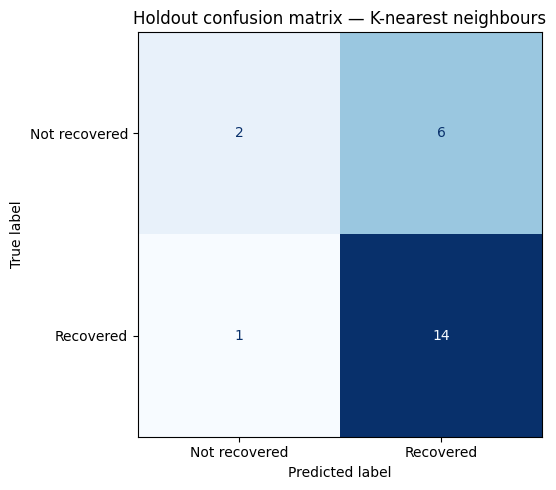

In [5]:
best_model=best_search.best_estimator_
y_pred=best_model.predict(X_test)
metrics={
    'accuracy':accuracy_score(y_test,y_pred),
    'balanced_accuracy':balanced_accuracy_score(y_test,y_pred),
    'precision':precision_score(y_test,y_pred,zero_division=0),
    'recall':recall_score(y_test,y_pred,zero_division=0),
    'f1':f1_score(y_test,y_pred,zero_division=0),
}
print('Selected:',best_name)
print('Held-out metrics:');display(pd.Series(metrics).round(3).to_frame('Score'))
print(classification_report(y_test,y_pred,labels=[0,1],target_names=['Not recovered','Recovered'],zero_division=0))
fig,ax=plt.subplots(figsize=(6,5))
ConfusionMatrixDisplay.from_predictions(y_test,y_pred,labels=[0,1],
    display_labels=['Not recovered','Recovered'],cmap='Blues',colorbar=False,ax=ax)
ax.set_title(f'Holdout confusion matrix — {best_name}')
fig.tight_layout()
fig.savefig(IMAGES/'falcon9_model_confusion_matrix.png',dpi=160,bbox_inches='tight')
plt.show()

## 5 · Export reproducible results

The exported `joblib` file is a **trusted-local Python artifact**. Only load model files from sources you trust. The saved pipeline includes all fitted preprocessing stages.

In [6]:
comparison_file=REPORTS/'falcon9_model_comparison.csv'
metrics_file=REPORTS/'falcon9_model_evaluation.json'
model_file=MODELS/'falcon9_recovery_classifier.joblib'
comparison.to_csv(comparison_file,index=False)
report={
    'dataset':str(SOURCE.as_posix()),'dataset_rows':int(len(df)),
    'train_rows':int(len(X_train)),'test_rows':int(len(X_test)),
    'features':features,'target':'Class (first-stage recovery)',
    'selection_metric':'5-fold stratified CV balanced accuracy (training data only)',
    'selected_model':best_name,'best_parameters':best_search.best_params_,
    'training_cv_balanced_accuracy':float(best_search.best_score_),
    'holdout_metrics':{k:float(v) for k,v in metrics.items()},
    'confusion_matrix_labels':[0,1],
    'confusion_matrix':confusion_matrix(y_test,y_pred,labels=[0,1]).tolist(),
    'limitations':['Small historical dataset','Random split does not test future-year generalisation',
                   'Retrospective source data may contain corrections','Outcome is booster recovery, not mission success']
}
metrics_file.write_text(json.dumps(report,indent=2),encoding='utf-8')
joblib.dump(best_model,model_file)
print('Saved:', comparison_file, metrics_file, model_file)

Saved: c:\Users\kanwa\Downloads\New folder\notebooks\reports\falcon9_model_comparison.csv c:\Users\kanwa\Downloads\New folder\notebooks\reports\falcon9_model_evaluation.json c:\Users\kanwa\Downloads\New folder\notebooks\models\falcon9_recovery_classifier.joblib


## 6 · Critical reflection

- **Historical-only:** The IBM dataset covers an earlier stage of Falcon 9 operations. It cannot justify claims about 2026 recovery rates.
- **Evaluation:** Random stratification is useful for coursework comparison, but a chronological train/test split would better simulate predicting later launches.
- **Class definition:** The course treats `None` outcomes as class 0. That can mix failed recovery attempts with missions where no landing was attempted; future work should distinguish those cases.
- **Dataset size:** A few different outcomes can materially change metrics. No operational readiness or causal claim is made.
- **Model interpretation:** A model may exploit changes in launch sites, mission mix and rocket versions over time.

**Next:** Compare the newly computed metrics with the archived 2023 final presentation. Retain historical results as provenance, not as current validated claims.